# Import libraries

In [1]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
import glob
from sklearn.manifold import TSNE

import os
from keras.models import load_model,Model
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (Dense, BatchNormalization, Reshape, Conv2D, Conv2DTranspose,Input,
                                     LeakyReLU, Dropout, Flatten, MaxPooling2D, GlobalAveragePooling2D,
                                     GlobalMaxPooling2D, SeparableConv2D, Activation, InputLayer,Add,GaussianNoise,RandomRotation,SpatialDropout2D,
                                     Lambda,RandomZoom,MaxPool2D,ReLU)
from tensorflow.keras.optimizers import Adam, Adamax, AdamW
from tensorflow.keras.losses import BinaryCrossentropy, CategoricalCrossentropy, SparseCategoricalCrossentropy
from tensorflow.keras.metrics import CategoricalAccuracy, AUC, Precision, Recall
from tensorflow.keras.applications import (Xception, EfficientNetB0, VGG19, ResNet50, ResNet50V2,MobileNetV2,
                                           DenseNet121, InceptionV3, MobileNetV3Small, MobileNetV3Large)
from tensorflow.keras.applications.xception import preprocess_input as xception_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess
from tensorflow.keras.callbacks import (LearningRateScheduler, ReduceLROnPlateau, ModelCheckpoint, EarlyStopping)
from tensorflow.keras.initializers import RandomNormal
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import plot_model, to_categorical
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers.schedules import ExponentialDecay

import shutil

import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils import shuffle, class_weight
import cv2

# Split Data

In [2]:
# Function to display images from the dataset
def display_sample_images(df, num_samples,class_name=None):
    plt.figure(figsize=(8, 10))
    plt.title(class_name)
    for i in range(num_samples):
        plt.subplot(4, num_samples, i + 1)
        img = plt.imread(df.iloc[i]['filepaths'])
        plt.imshow(img,cmap=plt.cm.gray)
        plt.axis('off')
    
    plt.tight_layout()
    plt.show()

In [3]:
def read_split(path,class_name):
    paths = glob.glob(f"{path}/*.jpg")
    df = pd.DataFrame({'filepaths':paths,"label":class_name})
    generate_set, val_set = train_test_split(df, train_size=0.80, random_state=123)
    return generate_set,val_set

In [4]:
def read(path,class_name):
    paths = glob.glob(f"{path}/*.jpg") + glob.glob(f"{path}/*.png")
    df = pd.DataFrame({'filepaths':paths,"label":class_name})
    return df

In [5]:
def Image_Data_Generator(df, batch_size=64):
    """
    Generates batches of images with preprocessing and augmentation for DCGAN training.
    """
    # Define ImageDataGenerator for preprocessing and augmentation
    generate_image_gen = tf.keras.preprocessing.image.ImageDataGenerator(
        preprocessing_function=lambda x: (x / 127.5) - 1.0,  
        # rotation_range=5,
        horizontal_flip=True, 
        # brightness_range=[0.9, 1.1],
        # shear_range=0.05,
        # zoom_range=0.05,
        # width_shift_range=0.01,
        # height_shift_range=0.01,
        fill_mode='nearest'
    )

    # Create data generator from the dataframe
    train_gen = generate_image_gen.flow_from_dataframe(
        dataframe=df,
        x_col="filepaths",
        y_col=None, 
        target_size=(128, 128), 
        color_mode='grayscale', 
        class_mode=None, 
        batch_size=batch_size,
        shuffle=True 
    )
    return train_gen


In [6]:
from typing import Tuple
import tensorflow as tf
import pandas as pd

def Image_Data_Generator_for_cnn(df_train, df_val, batch_size):

    # Image augmentation for training
    train_image_gen = tf.keras.preprocessing.image.ImageDataGenerator(
        rescale=1.0 / 255.0,
        #rotation_range=15,
       ## width_shift_range=0.03,
        #height_shift_range=0.03,
        #shear_range=0.0,
        # zoom_range=0.05,
        #horizontal_flip=True,
        #fill_mode='nearest',
       # brightness_range=[0.9, 1.1]
    )
    train_gen = train_image_gen.flow_from_dataframe(
        dataframe=df_train,
        x_col="filepaths",
        y_col="label",
        target_size=(128, 128),  # Fixed dimensions to match model input
        color_mode='grayscale',
        class_mode="categorical",
        batch_size=batch_size,
        shuffle=True,
    )
    
    # Validation data preprocessing
    val_image_gen = tf.keras.preprocessing.image.ImageDataGenerator(
        rescale=1.0 / 255.0
    )
    val_gen = val_image_gen.flow_from_dataframe(
        dataframe=df_val,
        x_col="filepaths",
        y_col="label",
        target_size=(128, 128),  # Fixed dimensions to match model input
        color_mode='grayscale',
        class_mode="categorical",
        batch_size=batch_size,
        shuffle=False
    )
    
    return train_gen, val_gen


In [7]:
def dispaly_image_generator(sample_images):
    plt.figure(figsize=(12, 12))
    for i in range(16):
        ax = plt.subplot(4, 4, i + 1)
        plt.imshow((sample_images[i] * 127.5 + 127.5).astype(np.uint8),cmap = 'gray')
        plt.axis("off")
    plt.show()

In [8]:
def plot_metrics(history):
    # Create a figure to hold the plots
    plt.figure(figsize=(12, 6))
    
    # Plot Accuracy
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    # Plot Loss
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()


    plt.tight_layout()  # Adjust subplots to fit into the figure area.
    plt.show()

In [9]:
def train_DCGAN(train_gen,ask_epoch, freq=500, batch_size=64, EPOCHS=10000):
    IMG_SHAPE = (128, 128, 1)
    LATENT_DIM = 400
    GRADIENT_PENALTY_WEIGHT = 10.0

    # ResNet Block for Generator
    def ResNetBlock(input_tensor, filters):
        x = Conv2DTranspose(filters, (4, 4), strides=(1, 1), padding='same')(input_tensor)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        x = Conv2DTranspose(filters, (4, 4), strides=(1, 1), padding='same')(x)
        x = BatchNormalization()(x)
        x = Add()([input_tensor, x])
        return LeakyReLU(alpha=0.2)(x)

    # Generator Model
    def Generator_Model():
        inputs = Input(shape=(LATENT_DIM,))
        
        x = Dense(8 * 8 * 512)(inputs)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        x = Reshape((8, 8, 512))(x)
        # x = GaussianNoise(0.05)(x)

        # x = Conv2DTranspose(512, (4, 4), strides=(2, 2), padding='same',kernel_regularizer=l2(0.0001))(x)
        # x = BatchNormalization()(x)
        # x = LeakyReLU(alpha=0.2)(x)
        # x = ResNetBlock(x, 512)

        x = Conv2DTranspose(256, (4, 4), strides=(2, 2), padding='same',kernel_regularizer=l2(0.0001))(x)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        x = ResNetBlock(x, 256)

        x = Conv2DTranspose(128, (4, 4), strides=(2, 2), padding='same',kernel_regularizer=l2(0.0001))(x)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        # x = GaussianNoise(0.2)(x)
        # x = Dropout(0.2)(x)

        x = Conv2DTranspose(64, (4, 4), strides=(2, 2), padding='same',kernel_regularizer=l2(0.0001))(x)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        # x = GaussianNoise(0.2)(x)
        # x = Dropout(0.2)(x)

        x = Conv2DTranspose(32, (4, 4), strides=(2, 2), padding='same',kernel_regularizer=l2(0.0001))(x)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        # x = Dropout(0.2)(x)

        outputs = Conv2DTranspose(1, (3, 3), padding='same', activation='tanh')(x)
        return Model(inputs, outputs)

    # Discriminator Model
    def Discriminator_Model():
        inputs = Input(shape=IMG_SHAPE)

        
        x = Conv2D(64, (3, 3), padding='same',kernel_regularizer=l2(0.0001))(inputs)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        x = MaxPooling2D(pool_size=(2, 2))(x)
        # x = Dropout(0.2)(x)
        # x = GaussianNoise(0.1)(x)
        
        x = Conv2D(128, (3, 3), padding='same',kernel_regularizer=l2(0.0001))(x)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        x = MaxPooling2D(pool_size=(2, 2))(x)
        # x = GaussianNoise(0.1)(x)
        # x = Dropout(0.2)(x)
        
        x = Conv2D(256, (3, 3), padding='same',kernel_regularizer=l2(0.0001))(x)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        x = MaxPooling2D(pool_size=(2, 2))(x)
        x = Dropout(0.1)(x)

        x = Conv2D(512, (3, 3), padding='same',kernel_regularizer=l2(0.0001))(x)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        x = MaxPooling2D(pool_size=(2, 2))(x)
        x = Dropout(0.1)(x)

        x = GlobalAveragePooling2D()(x)
        outputs = Dense(1)(x)  # No activation for WGAN-GP
        return Model(inputs, outputs)

    # Gradient Penalty Function
    def gradient_penalty(discriminator, real_images, fake_images):
        batch_size = tf.shape(real_images)[0]
        alpha = tf.random.uniform([batch_size, 1, 1, 1], 0.0, 1.0)
        interpolated = alpha * real_images + (1 - alpha) * fake_images
        with tf.GradientTape() as tape:
            tape.watch(interpolated)
            predictions = discriminator(interpolated, training=True)
        gradients = tape.gradient(predictions, [interpolated])[0]
        gradients_norm = tf.sqrt(tf.reduce_sum(tf.square(gradients), axis=[1, 2, 3]))
        penalty = tf.reduce_mean((gradients_norm - 1.0) ** 2)
        return penalty

    # DCGAN Model with Gradient Penalty
    class DCGAN(tf.keras.Model):
        def __init__(self, generator, discriminator, latent_dim=LATENT_DIM):
            super(DCGAN, self).__init__()
            self.generator = generator
            self.discriminator = discriminator
            self.latent_dim = latent_dim

        def compile(self, g_optimizer, d_optimizer, loss_fn):
            super(DCGAN, self).compile()
            self.g_optimizer = g_optimizer
            self.d_optimizer = d_optimizer
            self.loss_fn = loss_fn

        def train_step(self, data):
            real_images = tf.reshape(data, (-1,) + IMG_SHAPE)
            batch_size = tf.shape(real_images)[0]
            random_noise = tf.random.normal(shape=(batch_size, self.latent_dim))

            # Train Discriminator
            with tf.GradientTape() as tape:
                fake_images = self.generator(random_noise, training=True)
                pred_real = self.discriminator(real_images, training=True)
                pred_fake = self.discriminator(fake_images, training=True)
                gp = gradient_penalty(self.discriminator, real_images, fake_images)
                d_loss = tf.reduce_mean(pred_fake) - tf.reduce_mean(pred_real) + GRADIENT_PENALTY_WEIGHT * gp
            gradients = tape.gradient(d_loss, self.discriminator.trainable_variables)
            self.d_optimizer.apply_gradients(zip(gradients, self.discriminator.trainable_variables))

            # Train Generator
            with tf.GradientTape() as tape:
                fake_images = self.generator(random_noise, training=True)
                pred_fake = self.discriminator(fake_images, training=True)
                g_loss = -tf.reduce_mean(pred_fake)
            gradients = tape.gradient(g_loss, self.generator.trainable_variables)
            self.g_optimizer.apply_gradients(zip(gradients, self.generator.trainable_variables))

            return {'d_loss': d_loss, 'g_loss': g_loss}

    class UserPromptCallback(tf.keras.callbacks.Callback):
        def __init__(self, prompt_frequency):
            super(UserPromptCallback, self).__init__()
            self.prompt_frequency = prompt_frequency
            self.remaining_epochs = prompt_frequency

        def on_epoch_end(self, epoch, logs=None):
            self.remaining_epochs -= 1
            if self.remaining_epochs <= 0:
                response = input(f"Epoch {epoch + 1} completed. Do you want to stop training or add more epochs? (stop/add): ").strip().lower()
                if response == 'stop':
                    print("Stopping training as requested by the user.")
                    self.model.stop_training = True
                elif response == 'add':
                    additional_epochs = int(input("How many more epochs to add? ").strip())
                    print(f"Added {additional_epochs} more epochs.")
                    self.remaining_epochs = additional_epochs

    # Image Display Callback
    class ImageDisplayCallback(tf.keras.callbacks.Callback):
        def __init__(self, generator, display_frequency=freq, latent_dim=LATENT_DIM, num_images=10):
            super(ImageDisplayCallback, self).__init__()
            self.generator = generator
            self.display_frequency = display_frequency
            self.latent_dim = latent_dim
            self.num_images = num_images

        def on_epoch_end(self, epoch, logs=None):
            if (epoch + 1) % self.display_frequency == 0:
                self.display_images()

        def display_images(self):
            random_latent_vectors = tf.random.normal([self.num_images, self.latent_dim])
            generated_images = self.generator(random_latent_vectors, training=False)
            generated_images = (generated_images + 1) / 2.0  # Scale to [0, 1]

            plt.figure(figsize=(10, 5))
            for i in range(self.num_images):
                plt.subplot(2, 5, i + 1)
                plt.imshow(tf.squeeze(generated_images[i]), cmap="gray")
                plt.axis("off")
            plt.show()

    # Instantiate Models
    generator = Generator_Model()
    discriminator = Discriminator_Model()
    dcgan = DCGAN(generator=generator, discriminator=discriminator)

    # Optimizers and Compile
    generator_optimizer = Adam(learning_rate=0.0005, beta_1=0.5)
    discriminator_optimizer = Adam(learning_rate=0.0004, beta_1=0.5)
    dcgan.compile(
        g_optimizer=generator_optimizer,
        d_optimizer=discriminator_optimizer,
        loss_fn=BinaryCrossentropy(from_logits=True)
    )

    # Callbacks
    reduce_lr_g = ReduceLROnPlateau(monitor='g_loss', factor=0.2, patience=int(EPOCHS * 0.40), verbose=1, min_lr=1e-6)
    reduce_lr_d = ReduceLROnPlateau(monitor='d_loss', factor=0.2, patience=int(EPOCHS * 0.40), verbose=1, min_lr=1e-6)
    image_display_callback = ImageDisplayCallback(generator=generator, display_frequency=freq)
    user_prompt_callback = UserPromptCallback(prompt_frequency=ask_epoch)

    # Train the DCGAN
    history = dcgan.fit(
        train_gen,
        epochs=EPOCHS,
        batch_size=batch_size,
        callbacks=[ image_display_callback,user_prompt_callback]
    )
    return dcgan


In [10]:
import tensorflow as tf
import os
from PIL import Image

def generate_and_save_images(generator, subfolder_name, num_images=10000, latent_dim=400, batch_size=128):
    # Create the main directory 'generated_image'
    output_dir = "Dataset"
    os.makedirs(output_dir, exist_ok=True)
    
    # Create the user-specified subfolder inside 'generated_image'
    subfolder = os.path.join(output_dir, subfolder_name)
    os.makedirs(subfolder, exist_ok=True)

    num_batches = num_images // batch_size
    remaining_images = num_images % batch_size

    image_count = 0

    # Generate images in batches
    for batch in range(num_batches):
        # Generate random latent vectors for the batch
        random_latent_vectors = tf.random.normal([batch_size, latent_dim])
        
        # Generate images using the trained Generator
        generated_images = generator(random_latent_vectors, training=False)
        
        # Scale images from [-1, 1] to [0, 255] for saving
        generated_images = (generated_images + 1) * 127.5
        generated_images = tf.clip_by_value(generated_images, 0, 255)
        generated_images = tf.cast(generated_images, tf.uint8)

        # Save each generated image with the subfolder name and image number
        for i in range(batch_size):
            img_array = generated_images[i].numpy()
            img = Image.fromarray(img_array.squeeze(), mode="L")  # Assuming grayscale
            img.save(os.path.join(subfolder, f"{subfolder_name}_{image_count + 1}.png"))  # Using subfolder name and number
            image_count += 1
            
        tf.keras.backend.clear_session()  # Clearing session after each batch (optional)

    # Handle remaining images (if any) in a smaller batch
    if remaining_images > 0:
        random_latent_vectors = tf.random.normal([remaining_images, latent_dim])
        generated_images = generator(random_latent_vectors, training=False)
        generated_images = (generated_images + 1) * 127.5
        generated_images = tf.clip_by_value(generated_images, 0, 255)
        generated_images = tf.cast(generated_images, tf.uint8)

        for i in range(remaining_images):
            img_array = generated_images[i].numpy()
            img = Image.fromarray(img_array.squeeze(), mode="L")
            img.save(os.path.join(subfolder, f"{subfolder_name}_{image_count + 1}.png"))
            image_count += 1
        tf.keras.backend.clear_session()  # Clearing session after the remaining batch (optional)

    print(f"{num_images} images saved in '{subfolder}' directory.")



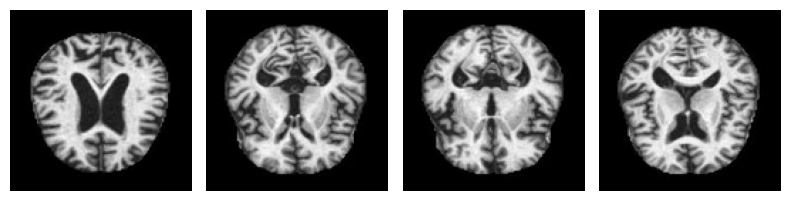

In [11]:
Moderate_Demented_path = r'/kaggle/input/alzheimer/Dataset/Moderate_Demented'
Moderate_generate_set,Moderate_val_set = read_split(Moderate_Demented_path,"Moderate_Demented")
display_sample_images(Moderate_generate_set, num_samples=4,class_name = "Moderate_Demented")

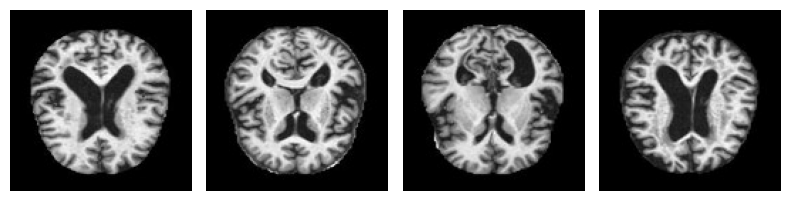

In [12]:
Mild_Demented_path = r'/kaggle/input/alzheimer/Dataset/Mild_Demented'
Mild_generate_set,Mild_val_set = read_split(Mild_Demented_path,"Mild_Demented")
display_sample_images(Mild_generate_set, num_samples=4,class_name = "Mild_Demented")

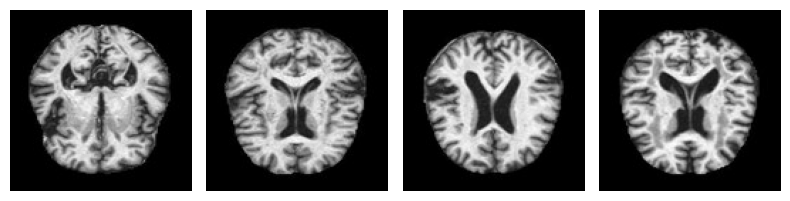

In [13]:
Very_Mild_Demented_path = r'/kaggle/input/alzheimer/Dataset/Very_Mild_Demented'
Very_Mild_generate_set,Very_Mild_val_set = read_split(Very_Mild_Demented_path,"Very_Mild_Demented")
display_sample_images(Very_Mild_generate_set, num_samples=4,class_name = "Very_Mild_Demented")

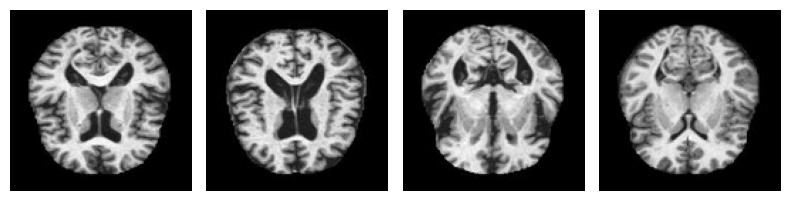

In [14]:
Non_Demented_path = r'/kaggle/input/alzheimer/Dataset/Non_Demented'
Non_generate_set,Non_val_set = read_split(Non_Demented_path,"Non_Demented")
display_sample_images(Non_generate_set, num_samples=4,class_name = "Non_Demented")

In [ ]:
Moderate_train_gen = Image_Data_Generator(Moderate_generate_set,batch_size = 51)
sample_images = next(Moderate_train_gen)
dispaly_image_generator(sample_images)

In [ ]:
Moderate_model = train_DCGAN(Moderate_train_gen,ask_epoch=500,freq = 200,EPOCHS = 3000,batch_size = 51)

In [ ]:
Mild_train_gen = Image_Data_Generator(Mild_generate_set,batch_size = 64)
sample_images = next(Mild_train_gen)
dispaly_image_generator(sample_images)

In [ ]:
Mild_model = train_DCGAN(Mild_train_gen,ask_epoch=32,freq = 16,batch_size = 64,EPOCHS = 352)

In [ ]:
Very_Mild_train_gen = Image_Data_Generator(Very_Mild_generate_set,batch_size = 64)
sample_images = next(Very_Mild_train_gen)
dispaly_image_generator(sample_images)

In [ ]:
Very_model = train_DCGAN(Very_Mild_train_gen,ask_epoch=40,batch_size = 64,EPOCHS = 200,freq = 5)

In [ ]:
Non_Mild_train_gen = Image_Data_Generator(Non_generate_set,batch_size = 64)
sample_images= next(Non_Mild_train_gen)
dispaly_image_generator(sample_images)

In [ ]:
Non_model = train_DCGAN(Non_Mild_train_gen,ask_epoch = 10,batch_size = 64,EPOCHS = 150,freq = 5)

In [37]:
# Moderate_model.generator.save("Moderate_generator.h5")
generate_and_save_images(load_model('/kaggle/input/moderate/keras/default/1/Moderate_generator (1).h5'),num_images=9949,subfolder_name='Moderate_Demented',batch_size = 256)

9949 images saved in 'Dataset/Moderate_Demented' directory.


In [38]:
# Mild_model.generator.save("Mild_generator.h5")
generate_and_save_images(load_model('/kaggle/input/mild/keras/default/1/Mild_generator (1).h5'),num_images=9284,subfolder_name='Mild_Demented',batch_size = 256)

9284 images saved in 'Dataset/Mild_Demented' directory.


In [39]:
# Very_model.generator.save("Very_generator.h5")
generate_and_save_images(load_model('/kaggle/input/very/keras/default/1/Very_generator (1).h5'),num_images=8208,subfolder_name='Very_Mild_Demented',batch_size = 256)

8208 images saved in 'Dataset/Very_Mild_Demented' directory.


In [40]:
# Non_model.generator.save("Non_generator.h5")
generate_and_save_images(load_model('/kaggle/input/non/keras/default/1/Non_generator (1).h5'),num_images=7440,subfolder_name='Non_Demented',batch_size = 256)

7440 images saved in 'Dataset/Non_Demented' directory.


In [39]:
Moderate_Demented_Original = read(r'/kaggle/input/alzheimer/Dataset/Moderate_Demented','Moderate_Demented')
Mild_Demented_Original = read(r'/kaggle/input/alzheimer/Dataset/Mild_Demented','Mild_Demented')
Very_Mild_Demented_Original = read(r'/kaggle/input/alzheimer/Dataset/Very_Mild_Demented','Very_Mild_Demented')
Non_Demented_Original = read(r'/kaggle/input/alzheimer/Dataset/Non_Demented','Non_Demented')
Original_Dataset = pd.concat([Moderate_Demented_Original, Mild_Demented_Original, Very_Mild_Demented_Original, Non_Demented_Original])
original_train,original_val = train_test_split(Original_Dataset, train_size=0.80, random_state=123)

Original_Dataset.head(5)

,filepaths,label
0,/kaggle/input/alzheimer/Dataset/Moderate_Demen...,Moderate_Demented
1,/kaggle/input/alzheimer/Dataset/Moderate_Demen...,Moderate_Demented
2,/kaggle/input/alzheimer/Dataset/Moderate_Demen...,Moderate_Demented
3,/kaggle/input/alzheimer/Dataset/Moderate_Demen...,Moderate_Demented
4,/kaggle/input/alzheimer/Dataset/Moderate_Demen...,Moderate_Demented


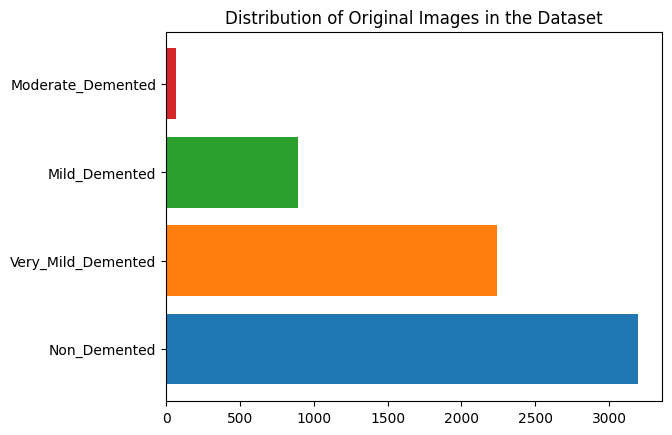

In [16]:
plt.barh(width = Original_Dataset['label'].value_counts(), y = Original_Dataset['label'].value_counts().index,color=plt.cm.tab10.colors,)
plt.title('Distribution of Original Images in the Dataset')
plt.show()

In [38]:
Moderate_Demented = read(r'/kaggle/working/Dataset/Moderate_Demented','Moderate_Demented')
Mild_Demented = read(r'/kaggle/working/Dataset/Mild_Demented','Mild_Demented')
Very_Mild_Demented = read(r'/kaggle/working/Dataset/Very_Mild_Demented','Very_Mild_Demented')
Non_Demented = read(r'/kaggle/working/Dataset/Non_Demented','Non_Demented')
combined_df = pd.concat([Moderate_Demented, Mild_Demented, Very_Mild_Demented, Non_Demented,Moderate_generate_set,Mild_generate_set,Very_Mild_generate_set,Non_generate_set])
shuffled_df = shuffle(combined_df, random_state=44)

shuffled_df.head(5)

,filepaths,label
1237,/kaggle/working/Dataset/Non_Demented/Non_Demen...,Non_Demented
703,/kaggle/input/alzheimer/Dataset/Non_Demented/n...,Non_Demented
5128,/kaggle/working/Dataset/Mild_Demented/Mild_Dem...,Mild_Demented
1341,/kaggle/working/Dataset/Moderate_Demented/Mode...,Moderate_Demented
5084,/kaggle/working/Dataset/Non_Demented/Non_Demen...,Non_Demented


In [18]:
val_set = pd.concat([Moderate_val_set, Mild_val_set, Very_Mild_val_set, Non_val_set])
val_set = shuffle(val_set, random_state=44)

val_set.head(5)

,filepaths,label
416,/kaggle/input/alzheimer/Dataset/Mild_Demented/...,Mild_Demented
1369,/kaggle/input/alzheimer/Dataset/Very_Mild_Deme...,Very_Mild_Demented
524,/kaggle/input/alzheimer/Dataset/Very_Mild_Deme...,Very_Mild_Demented
803,/kaggle/input/alzheimer/Dataset/Mild_Demented/...,Mild_Demented
200,/kaggle/input/alzheimer/Dataset/Mild_Demented/...,Mild_Demented


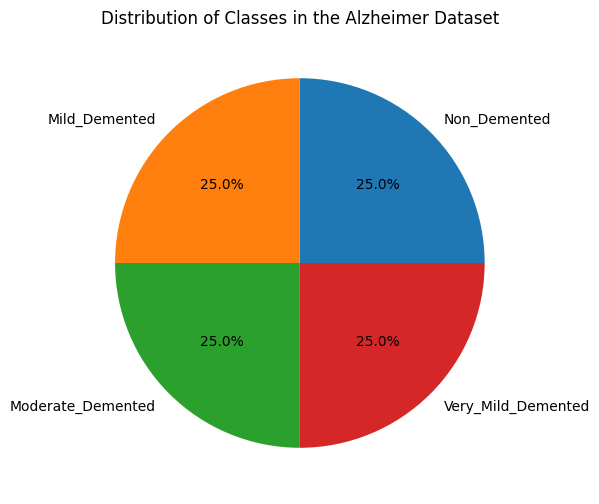

In [19]:
plt.figure(figsize= (10,6))
plt.pie(x = shuffled_df['label'].value_counts(), labels = shuffled_df['label'].value_counts().index,colors=plt.cm.tab10.colors,autopct='%1.1f%%')
plt.title('Distribution of Classes in the Alzheimer Dataset')
plt.show()

In [20]:
shuffled_df['label'].value_counts()

label
Non_Demented          10000
Mild_Demented         10000
Moderate_Demented     10000
Very_Mild_Demented    10000
Name: count, dtype: int64

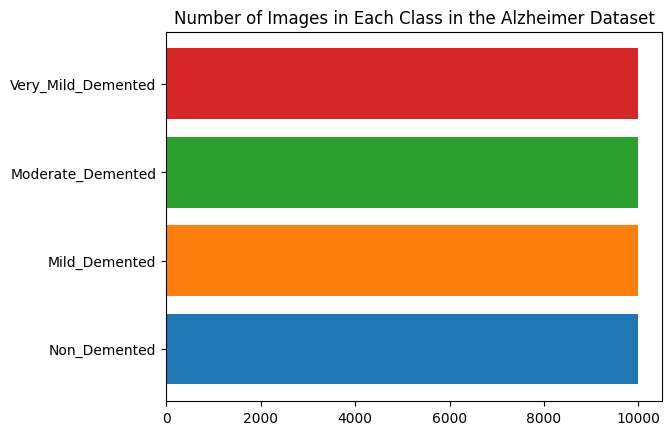

In [21]:
plt.barh(width = shuffled_df['label'].value_counts(), y = shuffled_df['label'].value_counts().index,color=plt.cm.tab10.colors,)
plt.title('Number of Images in Each Class in the Alzheimer Dataset')
plt.show()

In [22]:
df_train,df_val = Image_Data_Generator_for_cnn(shuffled_df,val_set,batch_size=32)

Found 40000 validated image filenames belonging to 4 classes.
Found 1281 validated image filenames belonging to 4 classes.


In [40]:
original_df_train,original_df_val = Image_Data_Generator_for_cnn(original_train,original_val,batch_size=32)

Found 5120 validated image filenames belonging to 4 classes.
Found 1280 validated image filenames belonging to 4 classes.


# Original + Generated Images

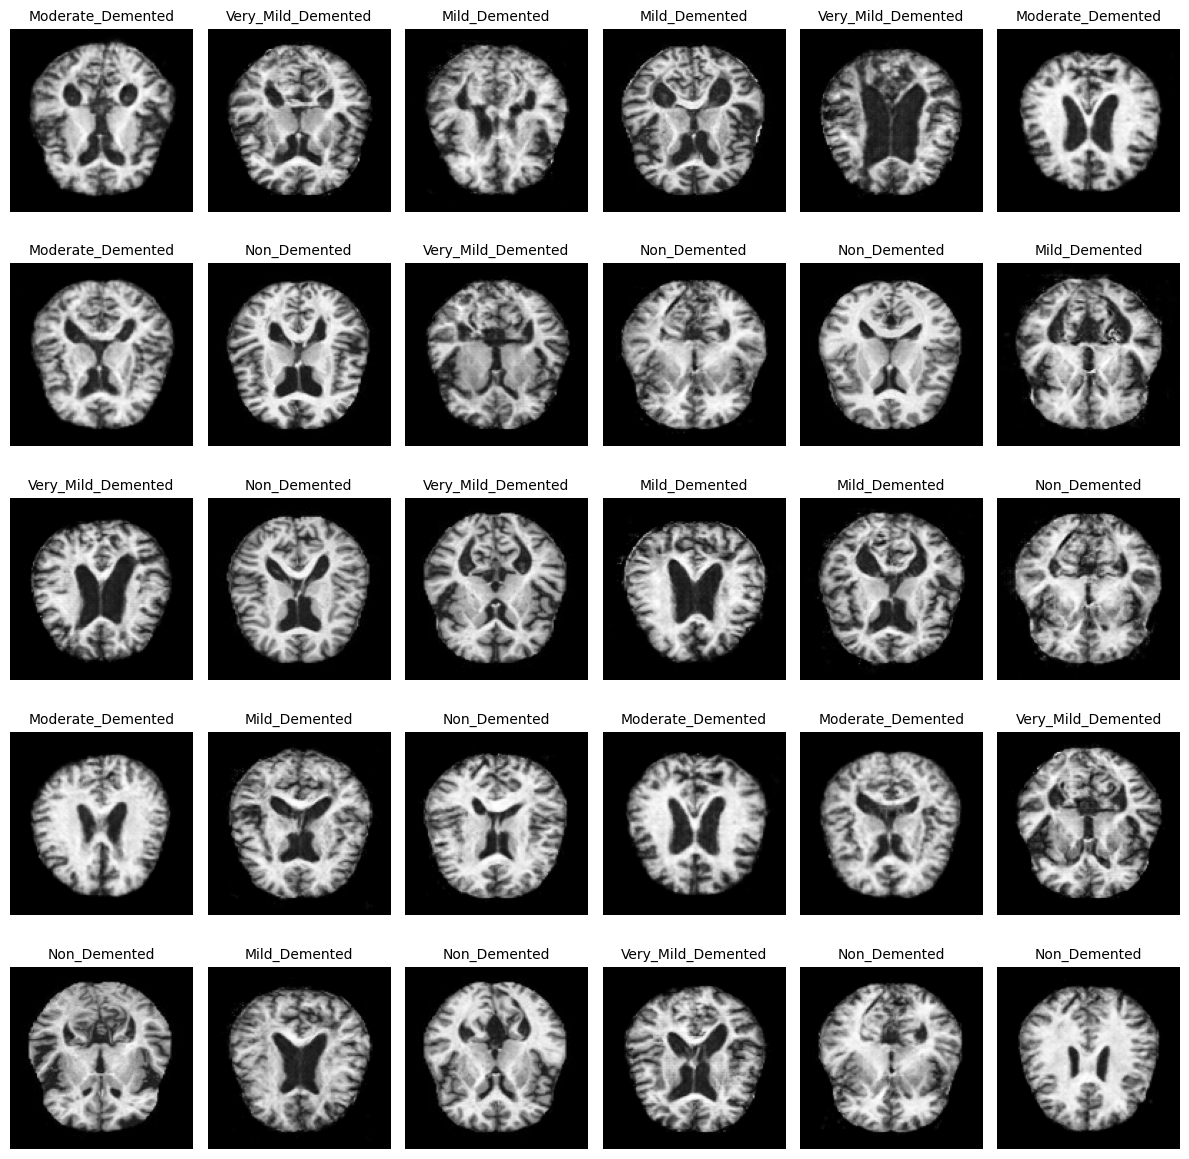

In [23]:
sample_images, image_labels = next(df_train)  # Assuming df_train is a DataGenerator
class_names = df_train.class_indices  # Mapping of class indices to names
class_names = {v: k for k, v in class_names.items()}  # Reverse mapping to get index->class

plt.figure(figsize=(12, 12))
for i in range(30):
    ax = plt.subplot(5, 6, i + 1)
    plt.imshow(sample_images[i], cmap='gray')  # Assuming grayscale images
    plt.axis("off")
    plt.title(class_names[image_labels[i].argmax()], fontsize=10)  # Get class name using argmax
plt.tight_layout()
plt.show()


# Original Images

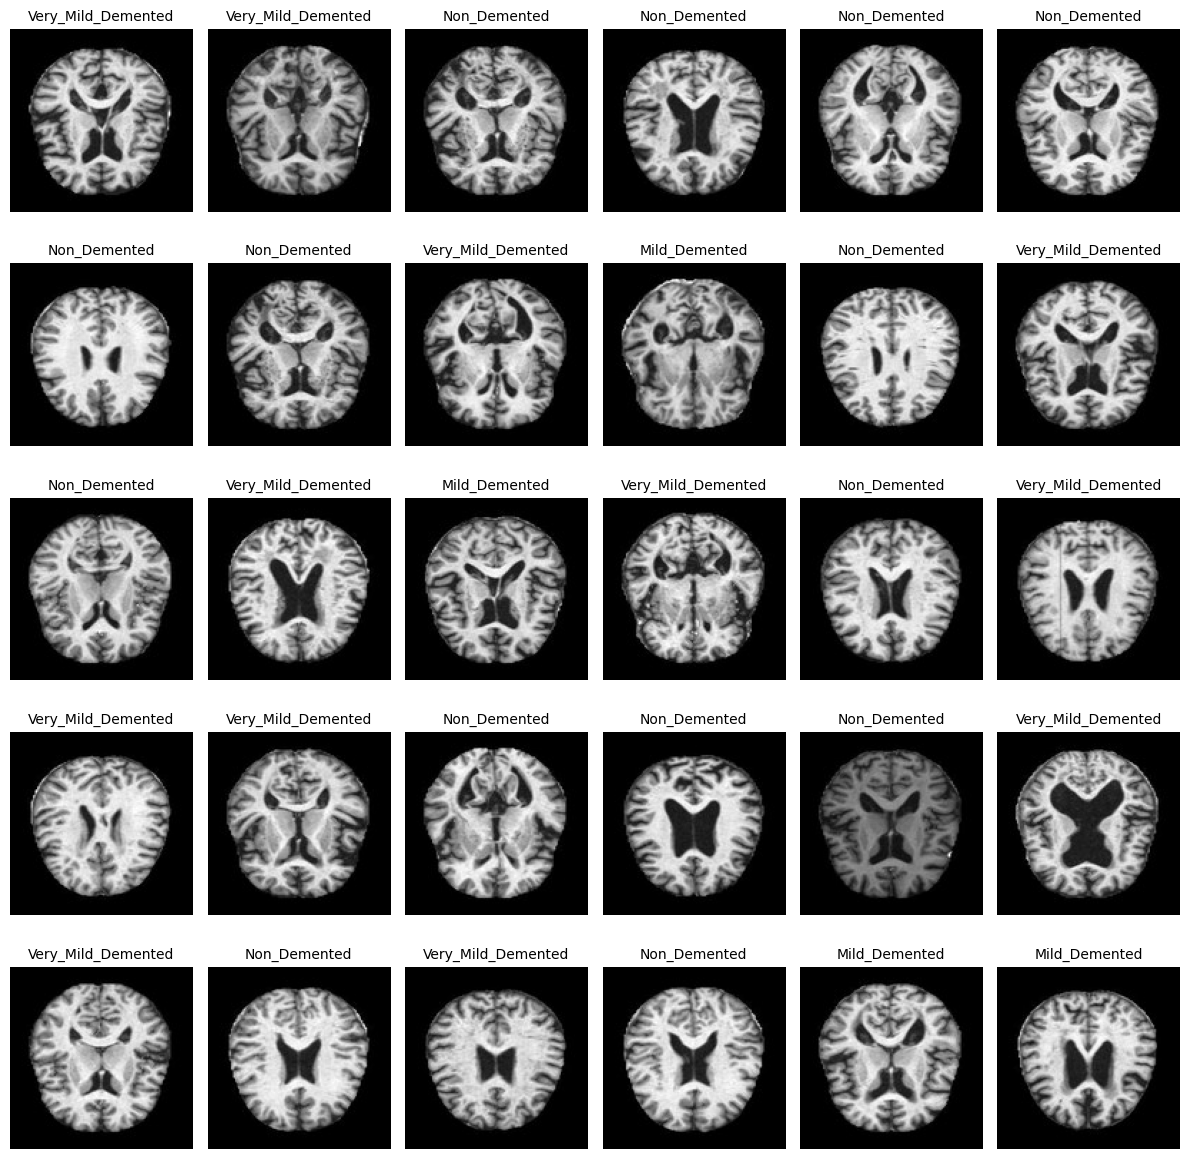

In [41]:
sample_images, image_labels = next(original_df_train)  # Assuming df_train is a DataGenerator
class_names = df_train.class_indices  # Mapping of class indices to names
class_names = {v: k for k, v in class_names.items()}  # Reverse mapping to get index->class

plt.figure(figsize=(12, 12))
for i in range(30):
    ax = plt.subplot(5, 6, i + 1)
    plt.imshow(sample_images[i], cmap='gray')  # Assuming grayscale images
    plt.axis("off")
    plt.title(class_names[image_labels[i].argmax()], fontsize=10)  # Get class name using argmax
plt.tight_layout()
plt.show()


# CNN for Original Images

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_19 (Conv2D)                   │ (None, 128, 128, 16)        │             160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_52 (LeakyReLU)           │ (None, 128, 128, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_20 (Conv2D)                   │ (None, 128, 128, 16)        │           2,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_53 (LeakyReLU)           │ (None, 128, 128, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_20 (MaxPooling2D)      │ (None, 64, 64, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_28 (Dropout)                 │ (None, 64, 64, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_21 (Conv2D)                   │ (None, 64, 64, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_54 (LeakyReLU)           │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_22 (Conv2D)                   │ (None, 64, 64, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_55 (LeakyReLU)           │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_28               │ (None, 64, 64, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_21 (MaxPooling2D)      │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_29 (Dropout)                 │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_23 (Conv2D)                   │ (None, 32, 32, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_56 (LeakyReLU)           │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_24 (Conv2D)                   │ (None, 32, 32, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_57 (LeakyReLU)           │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_29               │ (None, 32, 32, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_22 (MaxPooling2D)      │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_30 (Dropout)                 │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 1,480,308 (5.65 MB)

 Trainable params: 1,477,556 (5.64 MB)

 Non-trainable params: 2,752 (10.75 KB)

Epoch 1/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 24s 72ms/step - accuracy: 0.3803 - loss: 3.2102 - val_accuracy: 0.3531 - val_loss: 4.6506 - learning_rate: 0.0010
Epoch 2/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 11s 68ms/step - accuracy: 0.4963 - loss: 2.6819 - val_accuracy: 0.3531 - val_loss: 3.6258 - learning_rate: 0.0010
Epoch 3/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 10s 62ms/step - accuracy: 0.5187 - loss: 2.4773 - val_accuracy: 0.3531 - val_loss: 4.3700 - learning_rate: 0.0010
Epoch 4/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 10s 62ms/step - accuracy: 0.5223 - loss: 2.3125 - val_accuracy: 0.4945 - val_loss: 2.4006 - learning_rate: 0.0010
Epoch 5/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - accuracy: 0.5155 - loss: 2.1588 - val_accuracy: 0.3531 - val_loss: 2.7772 - learning_rate: 0.0010
Epoch 6/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - accuracy: 0.5448 - loss: 1.9984 - val_accuracy: 0.5773 - val_loss: 2.0512 - learning_rate: 0.0010
Epoch 7/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 10s 63ms/step - accuracy: 0.5

Epoch 20 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  20


Added 20 more epochs.
160/160 ━━━━━━━━━━━━━━━━━━━━ 35s 215ms/step - accuracy: 0.6493 - loss: 1.3271 - val_accuracy: 0.5523 - val_loss: 1.6692 - learning_rate: 8.0000e-06
Epoch 21/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 10s 62ms/step - accuracy: 0.6441 - loss: 1.3224 - val_accuracy: 0.5617 - val_loss: 1.6299 - learning_rate: 1.6000e-06
Epoch 22/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 11s 64ms/step - accuracy: 0.6507 - loss: 1.3191 - val_accuracy: 0.5625 - val_loss: 1.6363 - learning_rate: 1.6000e-06
Epoch 23/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.6392 - loss: 1.3250
Epoch 23: ReduceLROnPlateau reducing learning rate to 3.200000264769187e-07.
160/160 ━━━━━━━━━━━━━━━━━━━━ 11s 64ms/step - accuracy: 0.6393 - loss: 1.3250 - val_accuracy: 0.5656 - val_loss: 1.6222 - learning_rate: 1.6000e-06
Epoch 24/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - accuracy: 0.6470 - loss: 1.3266 - val_accuracy: 0.5680 - val_loss: 1.6161 - learning_rate: 3.2000e-07
Epoch 24: early stopping
Restoring mo

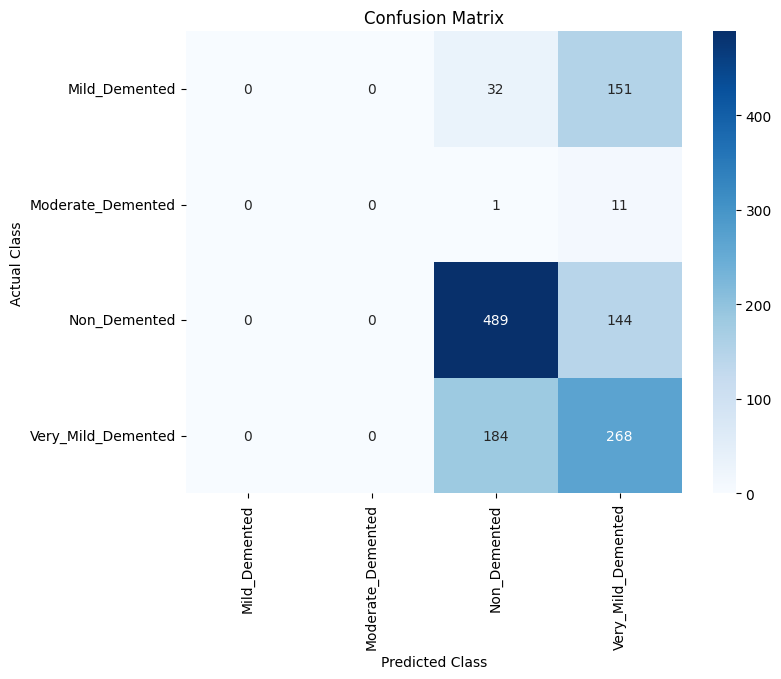

Classification Report:
                     precision    recall  f1-score   support

     Mild_Demented       0.00      0.00      0.00       183
 Moderate_Demented       0.00      0.00      0.00        12
      Non_Demented       0.69      0.77      0.73       633
Very_Mild_Demented       0.47      0.59      0.52       452

          accuracy                           0.59      1280
         macro avg       0.29      0.34      0.31      1280
      weighted avg       0.51      0.59      0.55      1280



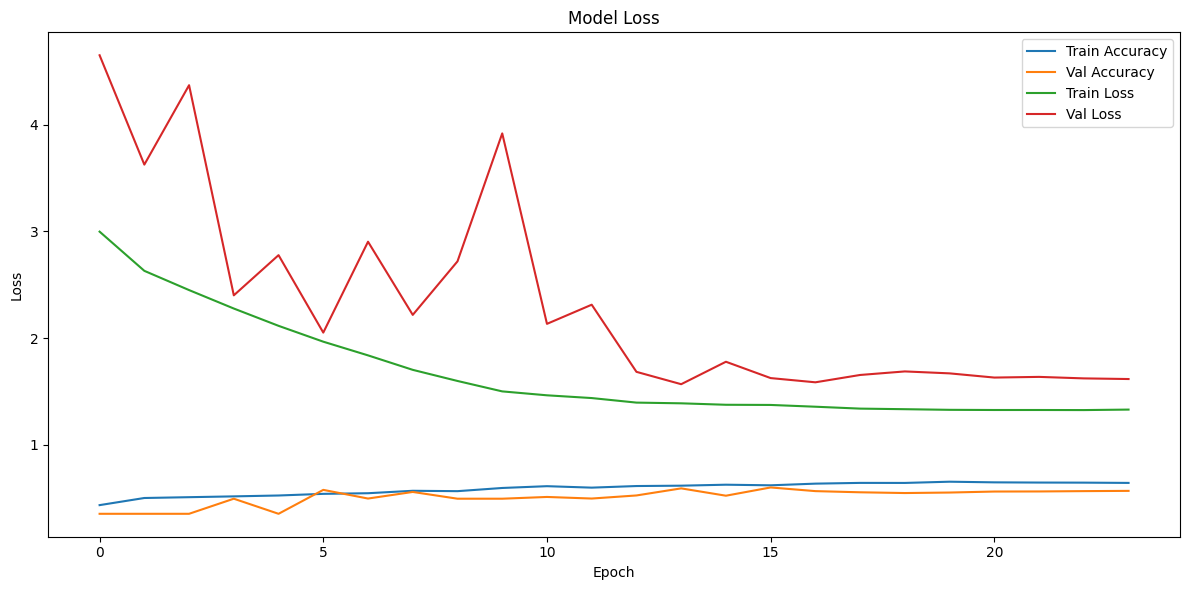

In [42]:
epochs = 100
IMAGE_SIZE = (128,128)
model = Sequential([
    Input(shape=(*IMAGE_SIZE, 1)),

    # Convolutional Block 1
    Conv2D(16, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    Conv2D(16, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    MaxPool2D(),
    Dropout(0.3),

    # Convolutional Block 2
    Conv2D(32, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    Conv2D(32, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    BatchNormalization(),
    MaxPool2D(),
    Dropout(0.4),

    # Convolutional Block 3
    Conv2D(64, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    Conv2D(64, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    BatchNormalization(),
    MaxPool2D(),
    Dropout(0.4),

    # Convolutional Block 4
    Conv2D(128, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    Conv2D(128, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    BatchNormalization(),
    MaxPool2D(),
    Dropout(0.5),

    # Convolutional Block 5
    Conv2D(256, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    Conv2D(256, 3, padding='same', kernel_regularizer=l2(1e-3), name='last_conv_layer'),
    LeakyReLU(alpha=0.01),
    BatchNormalization(),
    MaxPool2D(),
    GlobalAveragePooling2D(),

    # Fully Connected Layers
    Dense(512, kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    BatchNormalization(),
    Dropout(0.3),
    Dense(256, kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    BatchNormalization(),
    Dropout(0.2),
    Dense(128, kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    BatchNormalization(),
    Dropout(0.1),
    Dense(4, activation='softmax')
])

# Compile Model
model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()

# Callbacks
earlystopping = EarlyStopping(restore_best_weights=True, patience=10, verbose=1)
checkpoint = ModelCheckpoint('./original_data_mode_check.keras', save_best_only=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-7, verbose=1)

class UserPromptCallback(tf.keras.callbacks.Callback):
    def __init__(self, prompt_frequency, max_epochs=epochs):
        super(UserPromptCallback, self).__init__()
        self.prompt_frequency = prompt_frequency
        self.max_epochs = max_epochs
        self.remaining_epochs = prompt_frequency

    def on_epoch_end(self, epoch, logs=None):
        # Automatically stop if max_epochs is reached
        if epoch + 1 >= self.max_epochs:
            print(f"Reached maximum epoch {self.max_epochs}. Stopping training.")
            self.model.stop_training = True
            return
        
        # User prompt logic
        self.remaining_epochs -= 1
        if self.remaining_epochs <= 0:
            response = input(f"Epoch {epoch + 1} completed. Do you want to stop training or add more epochs? (stop/add): ").strip().lower()
            if response == 'stop':
                print("Stopping training as requested by the user.")
                self.model.stop_training = True
            elif response == 'add':
                additional_epochs = int(input("How many more epochs to add? ").strip())
                print(f"Added {additional_epochs} more epochs.")
                self.remaining_epochs = additional_epochs
user_prompt_callback = UserPromptCallback(prompt_frequency= 20)

# Train the model
history = model.fit(
    original_df_train,  # Grayscale preprocessing
    validation_data=original_df_val,
    batch_size=32,
    epochs=epochs,
    callbacks=[earlystopping, checkpoint, reduce_lr,user_prompt_callback]
)
# Save the model in the TensorFlow SavedModel format
model.save("original_data_model.keras")
# Load the best saved model after training
# model.load_weights("model.keras")

# Reset test generator before evaluation
original_df_val.reset()

# Evaluate on test data
test_loss, test_acc = model.evaluate(original_df_val)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

# Predictions for confusion matrix and classification report
y_true = original_df_val.classes  # True labels from the test generator
y_pred = np.argmax(model.predict(original_df_val), axis=1)  # Predicted class indices

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", 
            xticklabels=df_val.class_indices.keys(), 
            yticklabels=df_val.class_indices.keys())
plt.title('Confusion Matrix')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

# Classification Report
class_report = classification_report(y_true, y_pred, target_names=list(original_df_val.class_indices.keys()))
print("Classification Report:\n", class_report)
plot_model(model, to_file='model.png', show_shapes=True, show_layer_names=True)
plot_metrics(history)    

# CNN for Comined Images

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)                   │ (None, 128, 128, 16)        │             160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_13 (LeakyReLU)           │ (None, 128, 128, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_11 (Conv2D)                   │ (None, 128, 128, 16)        │           2,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_14 (LeakyReLU)           │ (None, 128, 128, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 64, 64, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 64, 64, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_12 (Conv2D)                   │ (None, 64, 64, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_15 (LeakyReLU)           │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_13 (Conv2D)                   │ (None, 64, 64, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_16 (LeakyReLU)           │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_7                │ (None, 64, 64, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_14 (Conv2D)                   │ (None, 32, 32, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_17 (LeakyReLU)           │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_15 (Conv2D)                   │ (None, 32, 32, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_18 (LeakyReLU)           │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_8                │ (None, 32, 32, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 1,480,308 (5.65 MB)

 Trainable params: 1,477,556 (5.64 MB)

 Non-trainable params: 2,752 (10.75 KB)

Epoch 1/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 51s 31ms/step - accuracy: 0.7117 - loss: 2.3099 - val_accuracy: 0.1405 - val_loss: 6.4602 - learning_rate: 0.0010
Epoch 2/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.9295 - loss: 0.9358 - val_accuracy: 0.1405 - val_loss: 10.7659 - learning_rate: 0.0010
Epoch 3/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 36s 28ms/step - accuracy: 0.9286 - loss: 0.5123 - val_accuracy: 0.5254 - val_loss: 1.2984 - learning_rate: 0.0010
Epoch 4/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.9326 - loss: 0.3650 - val_accuracy: 0.1975 - val_loss: 1.9785 - learning_rate: 0.0010
Epoch 5/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 36s 28ms/step - accuracy: 0.9302 - loss: 0.3622 - val_accuracy: 0.2178 - val_loss: 1.7396 - learning_rate: 0.0010
Epoch 6/100
1249/1250 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9332 - loss: 0.3241
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - 

... (4 outputs left out)

Epoch 60 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  20


Added 20 more epochs.
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 55s 44ms/step - accuracy: 0.9909 - loss: 0.0568 - val_accuracy: 0.9680 - val_loss: 0.1134 - learning_rate: 1.6000e-06
Epoch 61/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 36s 29ms/step - accuracy: 0.9921 - loss: 0.0542 - val_accuracy: 0.9774 - val_loss: 0.1048 - learning_rate: 1.6000e-06
Epoch 62/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.9924 - loss: 0.0555 - val_accuracy: 0.9781 - val_loss: 0.1058 - learning_rate: 1.6000e-06
Epoch 63/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.9919 - loss: 0.0554 - val_accuracy: 0.9758 - val_loss: 0.1070 - learning_rate: 1.6000e-06
Epoch 64/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 36s 28ms/step - accuracy: 0.9914 - loss: 0.0569 - val_accuracy: 0.9805 - val_loss: 0.1025 - learning_rate: 1.6000e-06
Epoch 65/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.9922 - loss: 0.0541 - val_accuracy: 0.9781 - val_loss: 0.1003 - learning_rate: 1.6000e-06
Epoch 66/100
1250/1

Epoch 80 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  20


Added 20 more epochs.
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 55s 44ms/step - accuracy: 0.9939 - loss: 0.0501 - val_accuracy: 0.9820 - val_loss: 0.0920 - learning_rate: 1.0000e-07
Epoch 81/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 36s 29ms/step - accuracy: 0.9928 - loss: 0.0524 - val_accuracy: 0.9828 - val_loss: 0.0913 - learning_rate: 1.0000e-07
Epoch 82/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.9932 - loss: 0.0518 - val_accuracy: 0.9820 - val_loss: 0.0924 - learning_rate: 1.0000e-07
Epoch 83/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.9928 - loss: 0.0518 - val_accuracy: 0.9774 - val_loss: 0.0940 - learning_rate: 1.0000e-07
Epoch 84/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 36s 28ms/step - accuracy: 0.9937 - loss: 0.0522 - val_accuracy: 0.9820 - val_loss: 0.0922 - learning_rate: 1.0000e-07
Epoch 85/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.9927 - loss: 0.0532 - val_accuracy: 0.9805 - val_loss: 0.0926 - learning_rate: 1.0000e-07
Epoch 86/100
1250/1

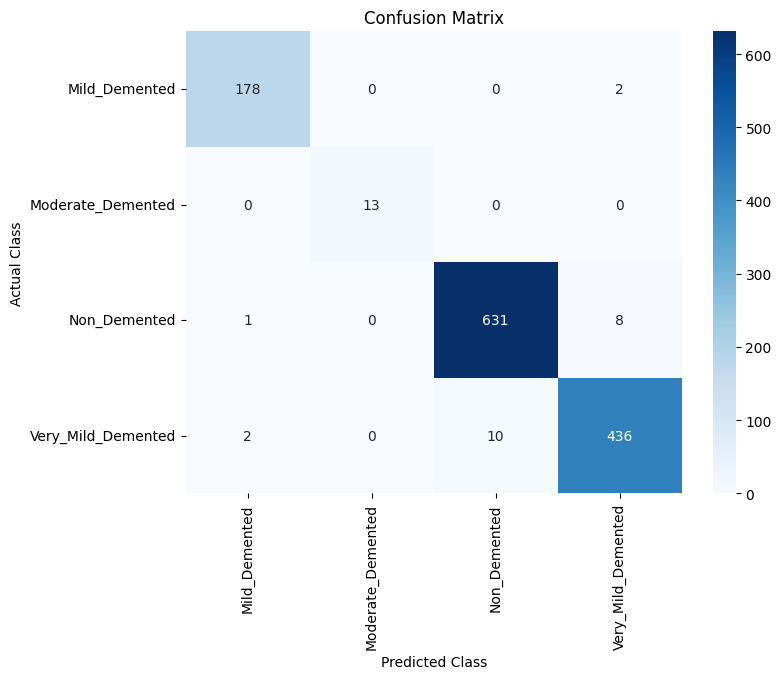

Classification Report:
                     precision    recall  f1-score   support

     Mild_Demented       0.98      0.99      0.99       180
 Moderate_Demented       1.00      1.00      1.00        13
      Non_Demented       0.98      0.99      0.99       640
Very_Mild_Demented       0.98      0.97      0.98       448

          accuracy                           0.98      1281
         macro avg       0.99      0.99      0.99      1281
      weighted avg       0.98      0.98      0.98      1281



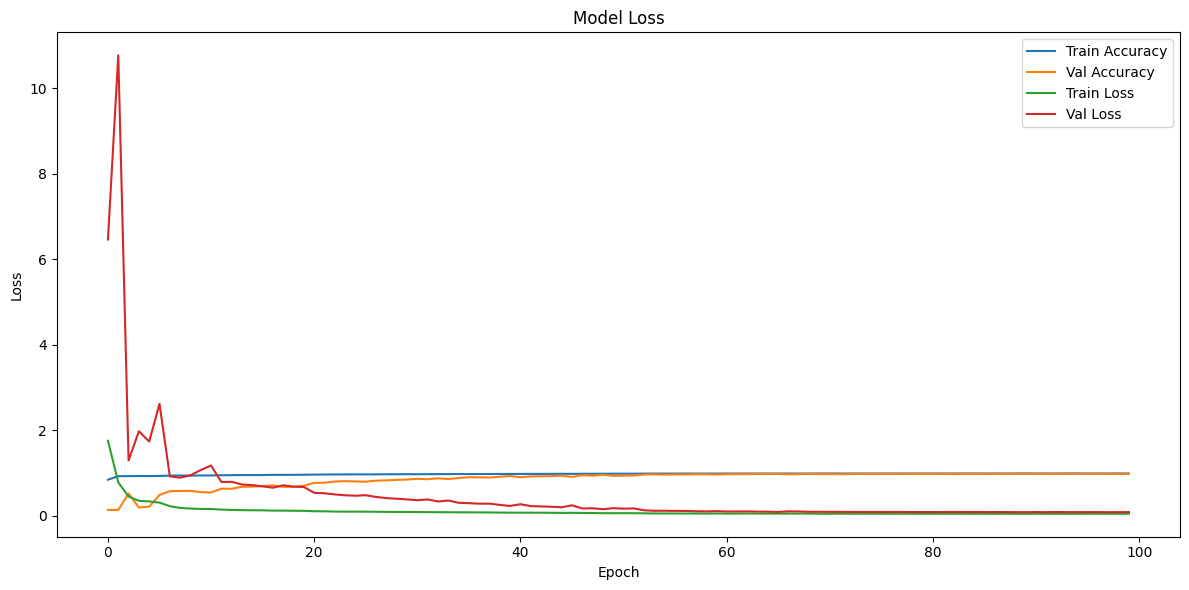

In [26]:
epochs = 100
IMAGE_SIZE = (128,128)
model = Sequential([
    Input(shape=(*IMAGE_SIZE, 1)),

    # Convolutional Block 1
    Conv2D(16, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    Conv2D(16, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    MaxPool2D(),
    Dropout(0.3),

    # Convolutional Block 2
    Conv2D(32, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    Conv2D(32, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    BatchNormalization(),
    MaxPool2D(),
    Dropout(0.4),

    # Convolutional Block 3
    Conv2D(64, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    Conv2D(64, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    BatchNormalization(),
    MaxPool2D(),
    Dropout(0.4),

    # Convolutional Block 4
    Conv2D(128, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    Conv2D(128, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    BatchNormalization(),
    MaxPool2D(),
    Dropout(0.5),

    # Convolutional Block 5
    Conv2D(256, 3, padding='same', kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    Conv2D(256, 3, padding='same', kernel_regularizer=l2(1e-3), name='last_conv_layer'),
    LeakyReLU(alpha=0.01),
    BatchNormalization(),
    MaxPool2D(),
    GlobalAveragePooling2D(),

    # Fully Connected Layers
    Dense(512, kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    BatchNormalization(),
    Dropout(0.3),
    Dense(256, kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    BatchNormalization(),
    Dropout(0.2),
    Dense(128, kernel_regularizer=l2(1e-3)),
    LeakyReLU(alpha=0.01),
    BatchNormalization(),
    Dropout(0.1),
    Dense(4, activation='softmax')
])

# Compile Model
model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()

# Callbacks
earlystopping = EarlyStopping(restore_best_weights=True, patience=10, verbose=1)
checkpoint = ModelCheckpoint('./model_check.keras', save_best_only=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-7, verbose=1)

class UserPromptCallback(tf.keras.callbacks.Callback):
    def __init__(self, prompt_frequency, max_epochs=epochs):
        super(UserPromptCallback, self).__init__()
        self.prompt_frequency = prompt_frequency
        self.max_epochs = max_epochs
        self.remaining_epochs = prompt_frequency

    def on_epoch_end(self, epoch, logs=None):
        # Automatically stop if max_epochs is reached
        if epoch + 1 >= self.max_epochs:
            print(f"Reached maximum epoch {self.max_epochs}. Stopping training.")
            self.model.stop_training = True
            return
        
        # User prompt logic
        self.remaining_epochs -= 1
        if self.remaining_epochs <= 0:
            response = input(f"Epoch {epoch + 1} completed. Do you want to stop training or add more epochs? (stop/add): ").strip().lower()
            if response == 'stop':
                print("Stopping training as requested by the user.")
                self.model.stop_training = True
            elif response == 'add':
                additional_epochs = int(input("How many more epochs to add? ").strip())
                print(f"Added {additional_epochs} more epochs.")
                self.remaining_epochs = additional_epochs
user_prompt_callback = UserPromptCallback(prompt_frequency= 20)

# Train the model
history = model.fit(
    df_train,  # Grayscale preprocessing
    validation_data=df_val,
    batch_size=32,
    epochs=epochs,
    callbacks=[earlystopping, checkpoint, reduce_lr,user_prompt_callback]
)
# Save the model in the TensorFlow SavedModel format
model.save("model.keras")
# Load the best saved model after training
# model.load_weights("model.keras")

# Reset test generator before evaluation
df_val.reset()

# Evaluate on test data
test_loss, test_acc = model.evaluate(df_val)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

# Predictions for confusion matrix and classification report
y_true = df_val.classes  # True labels from the test generator
y_pred = np.argmax(model.predict(df_val), axis=1)  # Predicted class indices

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", 
            xticklabels=df_val.class_indices.keys(), 
            yticklabels=df_val.class_indices.keys())
plt.title('Confusion Matrix')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

# Classification Report
class_report = classification_report(y_true, y_pred, target_names=list(df_val.class_indices.keys()))
print("Classification Report:\n", class_report)
plot_model(model, to_file='model.png', show_shapes=True, show_layer_names=True)
plot_metrics(history)    

In [5]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import os

# Configuration
BATCH_SIZE = 32
IMAGE_SIZE = (128, 128)
epochs = 50
# Data generator
generate_image_gen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1.0 / 255.0,
    validation_split=0.2,
    
)

# Train generator
train_gen = generate_image_gen.flow_from_directory(
    '/kaggle/working/Dataset',
    target_size=IMAGE_SIZE,
    color_mode='grayscale',
    class_mode=None,
    batch_size=BATCH_SIZE,
    shuffle=True,
    subset='training',
    seed=42
)

# Validation generator
val_gen = generate_image_gen.flow_from_directory(
    '//kaggle/working/Dataset',
    target_size=IMAGE_SIZE,
    color_mode='grayscale',
    class_mode=None,
    batch_size=BATCH_SIZE,
    shuffle=False,
    subset='validation',
    seed=42
)

# Function to prepare dataset arrays for training
def prepare_dataset(generator):
    images = []
    for batch in generator:
        images.append(batch)
        if len(images) * BATCH_SIZE >= generator.samples:
            break
    return np.concatenate(images)

# Load data
train_images = prepare_dataset(train_gen)
val_images = prepare_dataset(val_gen)

# Define the autoencoder architecture
def build_autoencoder(input_shape=(128, 128, 1)):
    input_img = tf.keras.Input(shape=input_shape)

    # Encoder
    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
    x = layers.MaxPooling2D((2, 2), padding='same')(x)
    x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2, 2), padding='same')(x)
    x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    encoded = layers.MaxPooling2D((2, 2), padding='same', name='latent_space')(x)

    # Decoder
    x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(encoded)
    x = layers.UpSampling2D((2, 2))(x)
    x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = layers.UpSampling2D((2, 2))(x)
    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = layers.UpSampling2D((2, 2))(x)
    decoded = layers.Conv2D(3, (3, 3), activation='sigmoid', padding='same')(x)

    # Autoencoder
    autoencoder = models.Model(input_img, decoded)

    # Encoder Model
    encoder = models.Model(input_img, encoded)

    return autoencoder, encoder
class UserPromptCallback(tf.keras.callbacks.Callback):
    def __init__(self, prompt_frequency, max_epochs=epochs):
        super(UserPromptCallback, self).__init__()
        self.prompt_frequency = prompt_frequency
        self.max_epochs = max_epochs
        self.remaining_epochs = prompt_frequency

    def on_epoch_end(self, epoch, logs=None):
        # Automatically stop if max_epochs is reached
        if epoch + 1 >= self.max_epochs:
            print(f"Reached maximum epoch {self.max_epochs}. Stopping training.")
            self.model.stop_training = True
            return
        
        # User prompt logic
        self.remaining_epochs -= 1
        if self.remaining_epochs <= 0:
            response = input(f"Epoch {epoch + 1} completed. Do you want to stop training or add more epochs? (stop/add): ").strip().lower()
            if response == 'stop':
                print("Stopping training as requested by the user.")
                self.model.stop_training = True
            elif response == 'add':
                additional_epochs = int(input("How many more epochs to add? ").strip())
                print(f"Added {additional_epochs} more epochs.")
                self.remaining_epochs = additional_epochs

# Build the model
autoencoder, encoder = build_autoencoder()
autoencoder.compile(optimizer='adam', loss=tf.keras.losses.MeanSquaredError())
autoencoder.summary()
encoder.summary()

user_prompt_callback = UserPromptCallback(prompt_frequency= 5)
# Train the autoencoder
history = autoencoder.fit(
    train_images, train_images,
    epochs=epochs,
    batch_size=BATCH_SIZE,
    validation_data=(val_images, val_images),
    callbacks=[user_prompt_callback]
)

latent_representations = encoder.predict(val_images)
print("Latent representation shape:", latent_representations.shape)

# Evaluate reconstruction error
reconstructed = autoencoder.predict(val_images)
reconstruction_error = np.mean((val_images - reconstructed) ** 2, axis=(1, 2, 3))

# Set an anomaly threshold
threshold = np.percentile(reconstruction_error, 95)
print("Reconstruction error threshold:", threshold)

# Identify anomalies
anomalies = reconstruction_error > threshold

# Visualize original vs reconstructed images for a few samples
def visualize_results(original, reconstructed, errors, threshold, num_samples=5):
    for i in range(num_samples):
        plt.figure(figsize=(10, 4))

        # Original image
        plt.subplot(1, 3, 1)
        plt.title("Original Image")
        plt.imshow(original[i])

        # Reconstructed image
        plt.subplot(1, 3, 2)
        plt.title("Reconstructed Image")
        plt.imshow(reconstructed[i])

        # Reconstruction error
        plt.subplot(1, 3, 3)
        plt.title(f"Reconstruction Error\n{'Anomalous' if errors[i] > threshold else 'Normal'}")
        plt.imshow((original[i] - reconstructed[i]) ** 2)

        plt.show()

# Visualize results
visualize_results(val_images, reconstructed, reconstruction_error, threshold)

# Reshape latent representations if needed
latent_flat = latent_representations.reshape(latent_representations.shape[0], -1)

# Apply t-SNE
tsne = TSNE(n_components=2, random_state=42)
latent_2d = tsne.fit_transform(latent_flat)

# Plot latent space
plt.figure(figsize=(8, 8))
plt.scatter(latent_2d[:, 0], latent_2d[:, 1], c=reconstruction_error, cmap='viridis', s=5)
plt.colorbar(label='Reconstruction Error')
plt.title("Latent Space Visualization")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.show()


Found 27907 images belonging to 4 classes.
Found 6974 images belonging to 4 classes.


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 128, 128, 1)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_14 (Conv2D)                   │ (None, 128, 128, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_15 (Conv2D)                   │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_16 (Conv2D)                   │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ latent_space (MaxPooling2D)          │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_17 (Conv2D)                   │ (None, 16, 16, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_6 (UpSampling2D)       │ (None, 32, 32, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_18 (Conv2D)                   │ (None, 32, 32, 64)          │          73,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_7 (UpSampling2D)       │ (None, 64, 64, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_19 (Conv2D)                   │ (None, 64, 64, 32)          │          18,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_8 (UpSampling2D)       │ (None, 128, 128, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_20 (Conv2D)                   │ (None, 128, 128, 3)         │             867 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 333,379 (1.27 MB)

 Trainable params: 333,379 (1.27 MB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

 Total params: 92,672 (362.00 KB)

 Trainable params: 92,672 (362.00 KB)

 Non-trainable params: 0 (0.00 B)

InternalError: Failed copying input tensor from /job:localhost/replica:0/task:0/device:CPU:0 to /job:localhost/replica:0/task:0/device:GPU:0 in order to run _EagerConst: Dst tensor is not initialized.

In [ ]:
autoencoder.save("autoencoder_model.h5")

In [ ]:
import numpy as np
import os, cv2
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Conv2D, Conv2DTranspose, Input, MaxPooling2D, UpSampling2D, BatchNormalization
from tensorflow.keras.models import Model
from sklearn.model_selection import train_test_split
import glob as gb
# Load and preprocess dataset
# Assuming image data is normalized to [0, 1] and images are resized to (128, 128, 3)
# Replace the dataset path with the actual path
images = []
labels = []

class_names = ['Non_Demented', 'Very_Mild_Demented', 'Mild_Demented', 'Moderate_Demented']
class_names_label = {class_name: i for i, class_name in enumerate(class_names)}

dataset_path = r'/kaggle/input/alzheimer/Dataset'
for folder in os.listdir(dataset_path):
    path = os.path.join(dataset_path, folder, '*.jpg')
    files = gb.glob(path)
    for file in files:
        image = cv2.imread(file)
        image = cv2.resize(image, (128, 128))  # Resize to 128x128
        image = image / 255.0  # Normalize to [0, 1]
        images.append(image)
        labels.append(class_names_label[folder])

# Convert to numpy arrays
images = np.array(images)
labels = np.array(labels)

# Split data into train and test sets
X_train, X_test, _, _ = train_test_split(images, labels, test_size=0.2, shuffle=True)

# Autoencoder Model

# Encoder
def build_encoder(input_shape):
    input_img = Input(shape=input_shape)
    
    # Convolutional layers for encoding
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
    x = MaxPooling2D((2, 2), padding='same')(x)  # Down-sample (128 -> 64)
    x = BatchNormalization()(x)
    
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = MaxPooling2D((2, 2), padding='same')(x)  # Down-sample (64 -> 32)
    x = BatchNormalization()(x)
    
    x = Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x = MaxPooling2D((2, 2), padding='same')(x)  # Down-sample (32 -> 16)
    x = BatchNormalization()(x)
    
    # Latent space representation
    latent = Conv2D(256, (3, 3), activation='relu', padding='same')(x)
    
    encoder = Model(input_img, latent, name="encoder")
    return encoder

# Decoder
def build_decoder(latent_shape):
    latent_input = Input(shape=latent_shape)
    
    # Convolutional layers for decoding
    x = Conv2D(128, (3, 3), activation='relu', padding='same')(latent_input)
    x = UpSampling2D((2, 2))(x)  # Up-sample (16 -> 32)
    x = BatchNormalization()(x)
    
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)  # Up-sample (32 -> 64)
    x = BatchNormalization()(x)
    
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)  # Up-sample (64 -> 128)
    x = BatchNormalization()(x)
    
    # Final layer to reconstruct the original image
    decoded = Conv2D(3, (3, 3), activation='sigmoid', padding='same')(x)  # Use sigmoid to ensure values between 0 and 1
    
    decoder = Model(latent_input, decoded, name="decoder")
    return decoder

# Input image dimensions
input_shape = (128, 128, 3)

# Build the encoder and decoder
encoder = build_encoder(input_shape)
decoder = build_decoder(encoder.output_shape[1:])

# Autoencoder model
autoencoder_input = Input(shape=input_shape)
encoded_img = encoder(autoencoder_input)
decoded_img = decoder(encoded_img)

autoencoder = Model(autoencoder_input, decoded_img, name="autoencoder")

# Compile the autoencoder
autoencoder.compile(optimizer=Adam(learning_rate=0.01), loss='mse', metrics=['accuracy'])

# Model summary
autoencoder.summary()

# Train the autoencoder
autoencoder.fit(X_train, X_train, epochs=200, batch_size=32, validation_data=(X_test, X_test))

# Visualize original and reconstructed images
def display_reconstructed_images(original_images, reconstructed_images, n=10):
    plt.figure(figsize=(20, 4))
    for i in range(n):
        # Display original image
        ax = plt.subplot(2, n, i + 1)
        plt.imshow(original_images[i])
        plt.title("Original")
        plt.axis("off")
        
        # Display reconstructed image
        ax = plt.subplot(2, n, i + n + 1)
        plt.imshow(reconstructed_images[i])
        plt.title("Reconstructed")
        plt.axis("off")
    plt.show()

# Select random images from the test set
n = 10
random_test_indices = np.random.randint(0, X_test.shape[0], size=n)

# Get original and reconstructed images
original_images = X_test[random_test_indices]
reconstructed_images = autoencoder.predict(original_images)

# Display the original and reconstructed images
display_reconstructed_images(original_images, reconstructed_images)


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, SeparableConv2D, MaxPooling2D, BatchNormalization,
    Flatten, Dropout, Dense, LeakyReLU, SpatialDropout2D,
    GaussianNoise, RandomRotation, RandomZoom, RandomFlip
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Model parameters
IMAGE_SIZE = (128, 128)
channelDim = 3

model = Sequential([
    Input(shape=(*IMAGE_SIZE, 3)),
    Conv2D(16, 3, activation='relu', padding='same'),
    Conv2D(16, 3, activation='relu', padding='same'),
    MaxPool2D(),
    Conv2D(32, 3, activation='relu', padding='same'),
    Conv2D(32, 3, activation='relu', padding='same'),
    BatchNormalization(),
    MaxPool2D(),
    Conv2D(64, 3, activation='relu', padding='same'),
    Conv2D(64, 3, activation='relu', padding='same'),
    BatchNormalization(),
    MaxPool2D(),
    Conv2D(128, 3, activation='relu', padding='same'),
    Conv2D(128, 3, activation='relu', padding='same'),
    BatchNormalization(),
    MaxPool2D(),
    Conv2D(256, 3, activation='relu', padding='same'),
    Conv2D(256, 3, activation='relu', padding='same', name = 'last_conv_layer'),
    BatchNormalization(),
    MaxPool2D(),
    Flatten(),
    Dropout(0.2),
    Dense(512, activation='relu'),
    BatchNormalization(),
    Dropout(0.7),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(4, activation='softmax')        
])
# Compile with gradient clipping (using only clipnorm)
optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.001,
    clipnorm=1.0  # Only using clipnorm
)

model.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

# Enhanced callbacks
earlystopping = EarlyStopping(
    monitor='val_loss',
    mode='min',
    patience=10,
    verbose=1,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    './best_model.weights.h5',
    monitor='val_loss',
    save_best_only=True,
    save_weights_only=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

# Training
history = model.fit(
    df_train,
    validation_data=df_val,
    batch_size=32,
    epochs=50,
    callbacks=[earlystopping, checkpoint, reduce_lr],
    shuffle=True
)
